In [370]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

# ***Reaidng the data***

In [371]:
df = pd.read_csv("egypt_House_prices.csv")
df.head()

,Type,Price,Bedrooms,Bathrooms,Area,Furnished,Level,Compound,Payment_Option,Delivery_Date,Delivery_Term,City
0,Duplex,4000000,3,3,400,No,7,Unknown,Cash,Ready to move,Finished,Nasr City
1,Apartment,4000000,3,3,160,No,10+,Unknown,Cash,Ready to move,Finished,Camp Caesar
2,Apartment,2250000,3,2,165,No,1,Unknown,Cash,Ready to move,Finished,Smoha
3,Apartment,1900000,3,2,230,No,10,Unknown,Cash,Ready to move,Finished,Nasr City
4,Apartment,5800000,2,3,160,No,Ground,Eastown,Cash,Ready to move,Semi Finished,New Cairo - El Tagamoa


# ***EDA***

In [372]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27361 entries, 0 to 27360
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Type            27361 non-null  object
 1   Price           27359 non-null  object
 2   Bedrooms        27158 non-null  object
 3   Bathrooms       27190 non-null  object
 4   Area            26890 non-null  object
 5   Furnished       27361 non-null  object
 6   Level           27361 non-null  object
 7   Compound        27361 non-null  object
 8   Payment_Option  27361 non-null  object
 9   Delivery_Date   27361 non-null  object
 10  Delivery_Term   27361 non-null  object
 11  City            27361 non-null  object
dtypes: object(12)
memory usage: 2.5+ MB


In [373]:
df.describe()

,Type,Price,Bedrooms,Bathrooms,Area,Furnished,Level,Compound,Payment_Option,Delivery_Date,Delivery_Term,City
count,27361,27359,27158,27190,26890,27361,27361,27361,27361,27361,27361,27361
unique,11,4182,12,12,786,3,14,560,4,10,5,183
top,Apartment,3000000,3,2,120,No,Unknown,Unknown,Cash or Installment,Ready to move,Finished,New Cairo - El Tagamoa
freq,8506,311,11803,9186,663,16500,10439,11068,10842,12142,14375,6789


In [374]:
df.isna().sum().sort_values(ascending=False)

,0
Area,471
Bedrooms,203
Bathrooms,171
Price,2
Type,0
Furnished,0
Level,0
Compound,0
Payment_Option,0
Delivery_Date,0


In [375]:
df.shape

(27361, 12)

In [376]:
df.duplicated().sum()

np.int64(1927)

In [377]:
df.drop_duplicates(inplace=True)
df.reset_index(drop = True , inplace = True)
df.duplicated().sum()

np.int64(0)

# ***Feature Engineering***

In [378]:
df.select_dtypes("object").columns

Index(['Type', 'Price', 'Bedrooms', 'Bathrooms', 'Area', 'Furnished', 'Level',
       'Compound', 'Payment_Option', 'Delivery_Date', 'Delivery_Term', 'City'],
      dtype='object')

In [379]:
df.head()

,Type,Price,Bedrooms,Bathrooms,Area,Furnished,Level,Compound,Payment_Option,Delivery_Date,Delivery_Term,City
0,Duplex,4000000,3,3,400,No,7,Unknown,Cash,Ready to move,Finished,Nasr City
1,Apartment,4000000,3,3,160,No,10+,Unknown,Cash,Ready to move,Finished,Camp Caesar
2,Apartment,2250000,3,2,165,No,1,Unknown,Cash,Ready to move,Finished,Smoha
3,Apartment,1900000,3,2,230,No,10,Unknown,Cash,Ready to move,Finished,Nasr City
4,Apartment,5800000,2,3,160,No,Ground,Eastown,Cash,Ready to move,Semi Finished,New Cairo - El Tagamoa


In [380]:
df["Type"].value_counts()

,count
Type,
Apartment,8038
Chalet,5959
Stand Alone Villa,4333
Town House,2842
Twin House,1665
Duplex,814
Standalone Villa,593
Penthouse,503
Twin house,457


In [381]:
df["Type"] = df["Type"].replace("Unknown" , np.nan)

In [382]:
df["Price"] = df["Price"].replace("Unknown" , np.nan)
df["Price"] =df["Price"].astype("float")

In [383]:
df["Bedrooms"].value_counts()

,count
Bedrooms,
3,10986
2,5066
4,4894
5,2199
1,938
6,732
7,233
8,81
10,53


In [384]:
df["Bedrooms"] = df["Bedrooms"].replace({"10+": 10, "Unknown": np.nan}).astype(float)

In [385]:
df["Bathrooms"].value_counts()

,count
Bathrooms,
2,8496
3,6932
4,3718
1,3402
5,1712
6,564
7,260
8,94
10,45


In [386]:
df["Bathrooms"] = df["Bathrooms"].replace({"10+": 10, "Unknown": np.nan}).astype(float)

In [387]:
df["Area"].value_counts()

,count
Area,
120,605
125,557
100,530
150,510
200,475
...,...
975,1
819,1
668,1


In [388]:
df["Area"] = df["Area"].replace("Unknown" , np.nan)
df["Area"] =df["Area"].astype("float")

In [389]:
df["Furnished"].value_counts()

,count
Furnished,
No,15358
Unknown,7840
Yes,2236


In [390]:
df["Furnished"] = df["Furnished"].replace("Unknown" , np.nan)
df["Furnished"].value_counts()

,count
Furnished,
No,15358
Yes,2236


In [391]:
df["Level"].value_counts()

,count
Level,
Unknown,9708
Ground,4353
2,3504
1,3325
3,1982
4,859
5,525
10+,254
6,217


In [392]:
df["Level"] = df["Level"].replace("Unknown" , np.nan)

In [393]:
df["Payment_Option"].value_counts()

,count
Payment_Option,
Cash or Installment,9890
Cash,9007
Installment,3645
Unknown Payment,2892


In [394]:
df["Payment_Option"] = df["Payment_Option"].replace("Unknown Payment" , np.nan)

In [395]:
df["Delivery_Date"].value_counts()

,count
Delivery_Date,
Ready to move,11362
Unknown,9230
soon,1553
2024,1004
2025,962
2023,655
2026,360
within 6 months,180
2022,124


In [396]:
df["Delivery_Date"] = df["Delivery_Date"].replace("Unknown" , np.nan)

In [397]:
df["Delivery_Term"].value_counts()

,count
Delivery_Term,
Finished,13271
Semi Finished,5065
Unknown,4477
Not Finished,1718
Core & Shell,903


In [398]:
df["Delivery_Term"] = df["Delivery_Term"].replace("Unknown" , np.nan)

In [399]:
df["City"].value_counts()

,count
City,
New Cairo - El Tagamoa,6390
North Coast,5771
Sheikh Zayed,2165
6th of October,1653
Ain Sukhna,1563
...,...
Only in Villas For Sale,1
Qanater al-Khairia,1
Bella,1


In [400]:
if "Unknown" in df["City"] :
    df["City"] = df["City"].replace("Unknown" , np.nan)

In [401]:
df["Level"] = df["Level"].replace({"10+": 10, "Highest": 11, "Ground": 0, "Unknown": np.nan}).astype(float)
df["Level"].value_counts()

,count
Level,
0.0,4353
2.0,3504
1.0,3325
3.0,1982
4.0,859
5.0,525
10.0,357
6.0,217
7.0,206


In [402]:
df.isna().sum().sort_values(ascending= False)

,0
Level,9708
Delivery_Date,9230
Furnished,7840
Payment_Option,2892
Area,467
Bedrooms,203
Bathrooms,171
Price,7
Type,4
Compound,0


<Axes: ylabel='Frequency'>

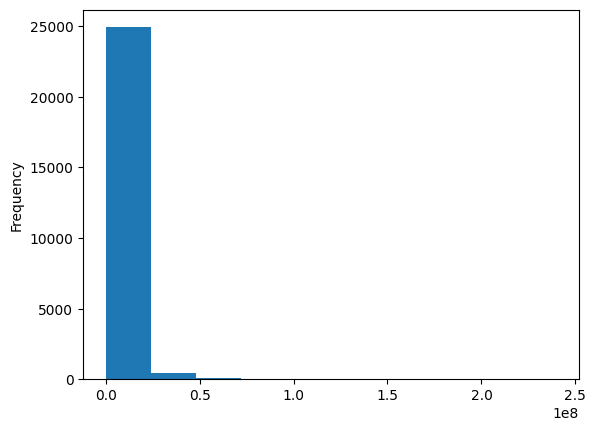

In [403]:
df["Price"].plot(kind ="hist")

In [404]:
df["Price"].skew()

np.float64(6.7758155896821535)

In [405]:
df = df.dropna(subset=["Price"])

In [406]:
df.dtypes

,0
Type,object
Price,float64
Bedrooms,float64
Bathrooms,float64
Area,float64
Furnished,object
Level,float64
Compound,object
Payment_Option,object
Delivery_Date,object


<Axes: ylabel='Frequency'>

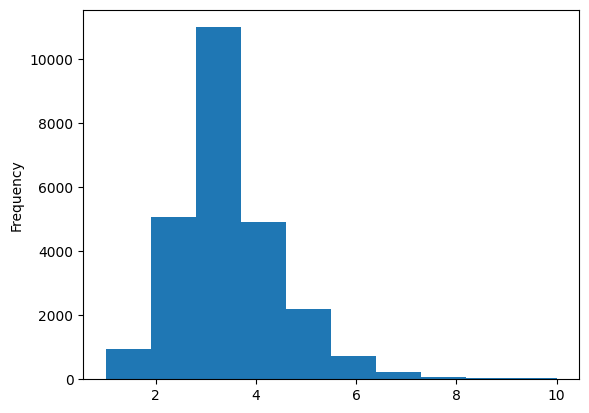

In [407]:
df["Bedrooms"].plot(kind ="hist")

In [408]:
df["Bedrooms"].skew()

np.float64(1.1789717892532545)

<Axes: ylabel='Frequency'>

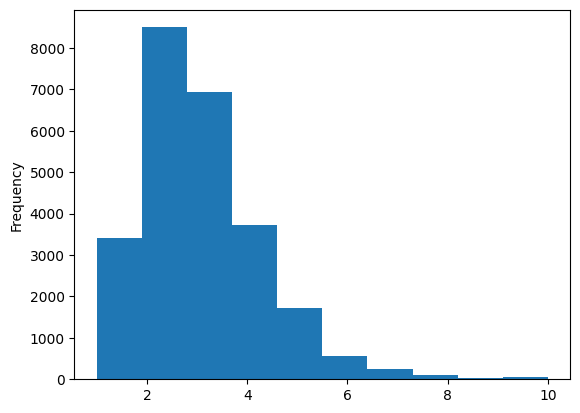

In [409]:
df["Bathrooms"].plot(kind ="hist")

In [410]:
df["Bathrooms"].skew()

np.float64(1.1535712112047651)

<Axes: ylabel='Frequency'>

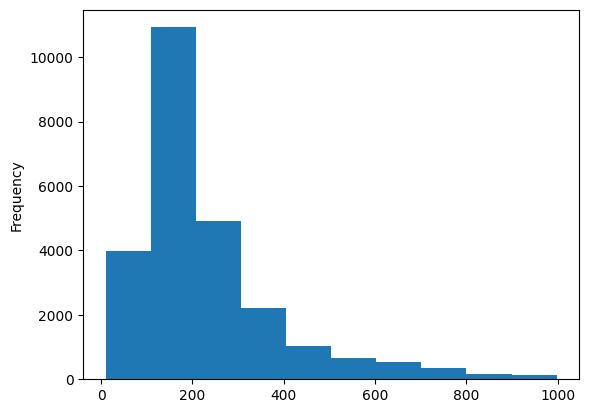

In [411]:
df["Area"].plot(kind ="hist")

In [412]:
df["Area"].skew()

np.float64(1.8995417616078316)

<Axes: xlabel='Bathrooms', ylabel='Price'>

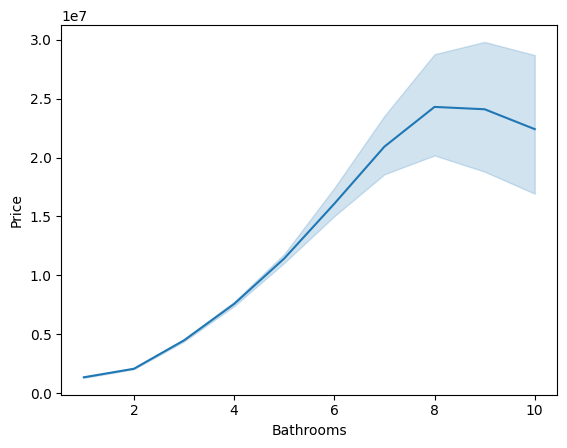

In [413]:
sns.lineplot(data=df,x='Bathrooms',y='Price')

<Axes: xlabel='Furnished', ylabel='count'>

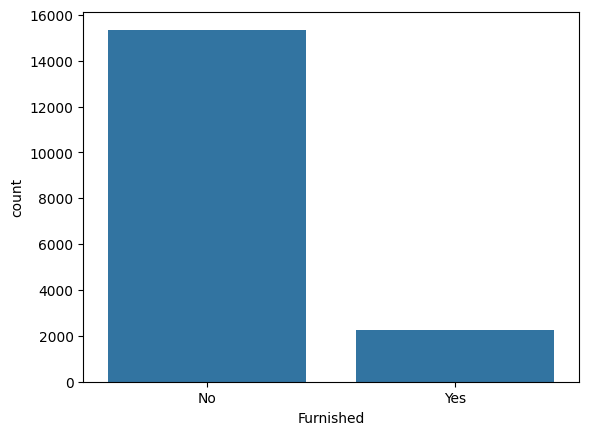

In [414]:
sns.countplot(data=df,x='Furnished')

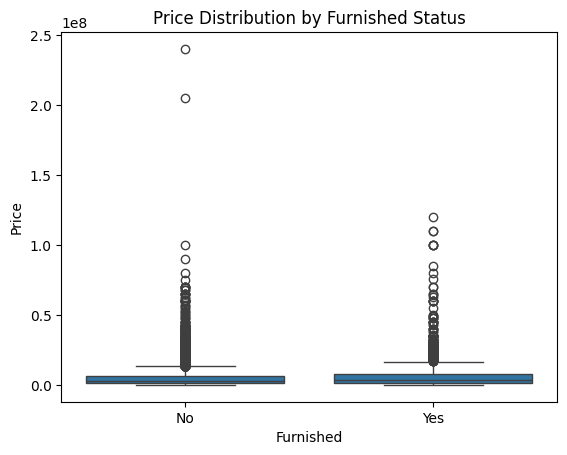

In [415]:
sns.boxplot(data=df, x="Furnished", y="Price")
plt.title("Price Distribution by Furnished Status")
plt.show()

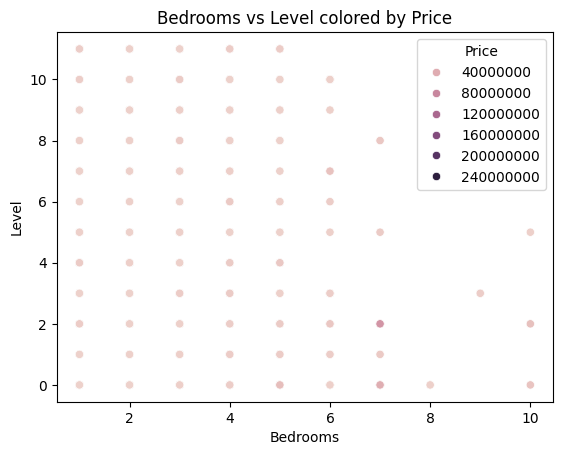

In [416]:
sns.scatterplot(
    data=df,
    x="Bedrooms",
    y="Level",
    hue="Price"
)
plt.title("Bedrooms vs Level colored by Price")
plt.show()

In [417]:
X = df.drop("Price", axis = 1 )
y = df["Price"]

In [418]:
numeric = [col for col in X.select_dtypes(["int",float]).columns]

obj = [col for col in X.select_dtypes("object").columns]

In [419]:
X[obj].head()

,Type,Furnished,Compound,Payment_Option,Delivery_Date,Delivery_Term,City
0,Duplex,No,Unknown,Cash,Ready to move,Finished,Nasr City
1,Apartment,No,Unknown,Cash,Ready to move,Finished,Camp Caesar
2,Apartment,No,Unknown,Cash,Ready to move,Finished,Smoha
3,Apartment,No,Unknown,Cash,Ready to move,Finished,Nasr City
4,Apartment,No,Eastown,Cash,Ready to move,Semi Finished,New Cairo - El Tagamoa


In [420]:
X[numeric].head()

,Bedrooms,Bathrooms,Area,Level
0,3.0,3.0,400.0,7.0
1,3.0,3.0,160.0,10.0
2,3.0,2.0,165.0,1.0
3,3.0,2.0,230.0,10.0
4,2.0,3.0,160.0,0.0


In [421]:
X.shape

(25427, 11)

In [422]:
X.isna().sum().sort_values(ascending= False)

,0
Level,9701
Delivery_Date,9226
Furnished,7835
Payment_Option,2888
Area,463
Bedrooms,199
Bathrooms,167
Type,0
Compound,0
Delivery_Term,0


In [423]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import LabelEncoder , OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer


from sklearn.ensemble import RandomForestRegressor, BaggingRegressor , VotingRegressor, ExtraTreesRegressor
from sklearn.ensemble import AdaBoostRegressor , GradientBoostingRegressor
from xgboost import XGBRegressor



from sklearn.svm import  SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [424]:
X.shape , y.shape

((25427, 11), (25427,))

In [425]:
for col in X :
    print("Column: ",col)
    print("Number of unique Value: ",X[col].nunique())
    print("*" * 20)


Column:  Type
Number of unique Value:  10
********************
Column:  Bedrooms
Number of unique Value:  10
********************
Column:  Bathrooms
Number of unique Value:  10
********************
Column:  Area
Number of unique Value:  785
********************
Column:  Furnished
Number of unique Value:  2
********************
Column:  Level
Number of unique Value:  12
********************
Column:  Compound
Number of unique Value:  560
********************
Column:  Payment_Option
Number of unique Value:  3
********************
Column:  Delivery_Date
Number of unique Value:  9
********************
Column:  Delivery_Term
Number of unique Value:  5
********************
Column:  City
Number of unique Value:  179
********************


In [426]:
X.head()

,Type,Bedrooms,Bathrooms,Area,Furnished,Level,Compound,Payment_Option,Delivery_Date,Delivery_Term,City
0,Duplex,3.0,3.0,400.0,No,7.0,Unknown,Cash,Ready to move,Finished,Nasr City
1,Apartment,3.0,3.0,160.0,No,10.0,Unknown,Cash,Ready to move,Finished,Camp Caesar
2,Apartment,3.0,2.0,165.0,No,1.0,Unknown,Cash,Ready to move,Finished,Smoha
3,Apartment,3.0,2.0,230.0,No,10.0,Unknown,Cash,Ready to move,Finished,Nasr City
4,Apartment,2.0,3.0,160.0,No,0.0,Eastown,Cash,Ready to move,Semi Finished,New Cairo - El Tagamoa


In [427]:
X_train , X_test , y_train , y_test = train_test_split(X , y , test_size= .3 , random_state= 1234)

In [428]:
categorical = Pipeline(steps= [
    ("impute", SimpleImputer(strategy= "most_frequent")),
    ("encoder" , OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))
])

numerical = Pipeline(steps= [
    ("impute", SimpleImputer(strategy= "median")),
    ("scaler" , MinMaxScaler(feature_range=(0,1)))
])

preprocessor = ColumnTransformer(transformers= [
    ("categorical" , categorical , obj),
    ("numerical" , numerical , numeric)
]
)

In [429]:
vote = VotingRegressor(
    estimators= [
        ('svr' , SVR()),
        ('rf' , RandomForestRegressor(random_state=1234)),
        ("bagg_svr" , BaggingRegressor(estimator= SVR()))
    ]
)

In [430]:
model = Pipeline(steps= [
    ("preprocessor" , preprocessor),
    ("model" , vote )
], verbose=True)

model.fit(X_train , y_train)

[Pipeline] ...... (step 1 of 2) Processing preprocessor, total=   0.1s
[Pipeline] ............. (step 2 of 2) Processing model, total= 1.2min


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('categorical',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OrdinalEncoder(handle_unknown='use_encoded_value',
                                                                                  unknown_value=-1))]),
                                                  ['Type', 'Furnished',
                                                   'Compound', 'Payment_Option',
                                                   'Delivery_Date',
                                                   'Delivery_Term', 'City']),
                                                 ('numerical',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   MinMaxScaler())]),
                                                  ['Bedrooms', 'Bathrooms',
                                                   'Area', 'Level'])])),
                ('model',
                 VotingRegressor(estimators=[('svr', SVR()),
                                             ('rf',
                                              RandomForestRegressor(random_state=1234)),
                                             ('bagg_svr',
                                              BaggingRegressor(estimator=SVR()))]))],
         verbose=True)

In [431]:
y_pred = model.predict(X_test)

In [432]:
print("Score _train:",model.score(X_train , y_train) )
print("Score _test:",model.score(X_test, y_test) )

Score _train: 0.45045216198244487
Score _test: 0.29532727093784306


In [433]:
print("MAE:",mean_absolute_error(y_test , y_pred))
print("MSE:",mean_squared_error(y_test , y_pred))
print("RMSE:",np.sqrt(mean_squared_error(y_test , y_pred)))
print("R2:",r2_score(y_test , y_pred))

MAE: 2742002.7795265615
MSE: 32090823260713.33
RMSE: 5664876.2793827485
R2: 0.29532727093784306


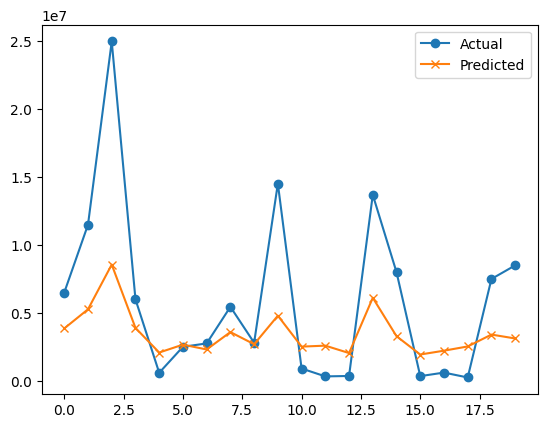

In [434]:
plt.plot(range(20) , y_test[:20] , marker = "o", label="Actual")
plt.plot(range(20) , y_pred[:20],  marker = "x", label="Predicted")
plt.legend()
plt.show()

In [435]:
model = Pipeline(steps= [
    ("preprocessor" , preprocessor),
    ("model" , XGBRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        random_state=1234,
        n_jobs=-1
    ) )
], verbose=True)

model.fit(X_train , y_train)

[Pipeline] ...... (step 1 of 2) Processing preprocessor, total=   0.1s
[Pipeline] ............. (step 2 of 2) Processing model, total=   0.1s


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('categorical',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OrdinalEncoder(handle_unknown='use_encoded_value',
                                                                                  unknown_value=-1))]),
                                                  ['Type', 'Furnished',
                                                   'Compound', 'Payment_Option',
                                                   'Delivery_Date',
                                                   'Delivery_Term', 'City']),
                                                 ('numerical',
                                                  Pipeline(steps=[('im...
                              gamma=None, grow_policy=None,
                              importance_type=None,
                              interaction_constraints=None, learning_rate=0.05,
                              max_bin=None, max_cat_threshold=None,
                              max_cat_to_onehot=None, max_delta_step=None,
                              max_depth=3, max_leaves=None,
                              min_child_weight=None, missing=nan,
                              monotone_constraints=None, multi_strategy=None,
                              n_estimators=100, n_jobs=-1,
                              num_parallel_tree=None, ...))],
         verbose=True)

In [436]:
y_pred = model.predict(X_test)

In [437]:
print("Score _train:",model.score(X_train , y_train) )
print("Score _test:",model.score(X_test, y_test) )

Score _train: 0.5632909268111421
Score _test: 0.5068727082415446


In [438]:
print("MAE:",mean_absolute_error(y_test , y_pred))
print("MSE:",mean_squared_error(y_test , y_pred))
print("RMSE:",np.sqrt(mean_squared_error(y_test , y_pred)))
print("R2:",r2_score(y_test , y_pred))

MAE: 2259797.8741152184
MSE: 22457035886596.582
RMSE: 4738885.511024357
R2: 0.5068727082415446


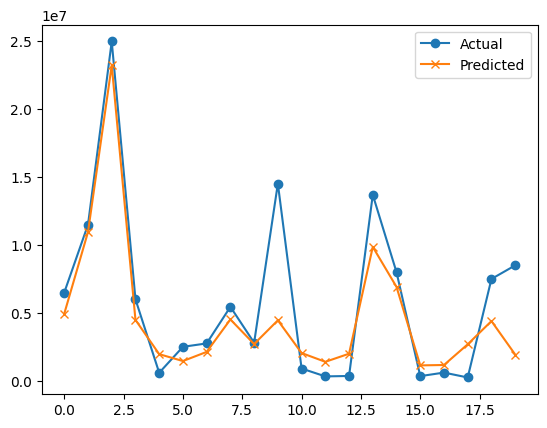

In [439]:
plt.plot(range(20) , y_test[:20] , marker = "o", label="Actual")
plt.plot(range(20) , y_pred[:20],  marker = "x", label="Predicted")
plt.legend()
plt.show()

In [440]:
model = Pipeline(steps= [
    ("preprocessor" , preprocessor),
    ("model" , RandomForestRegressor(
    n_estimators=300,
    max_depth=15,
    min_samples_leaf=5,
    max_features=0.5,
    n_jobs=-1,
    random_state=42)

    )
])

model.fit(X_train , y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('categorical',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OrdinalEncoder(handle_unknown='use_encoded_value',
                                                                                  unknown_value=-1))]),
                                                  ['Type', 'Furnished',
                                                   'Compound', 'Payment_Option',
                                                   'Delivery_Date',
                                                   'Delivery_Term', 'City']),
                                                 ('numerical',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   MinMaxScaler())]),
                                                  ['Bedrooms', 'Bathrooms',
                                                   'Area', 'Level'])])),
                ('model',
                 RandomForestRegressor(max_depth=15, max_features=0.5,
                                       min_samples_leaf=5, n_estimators=300,
                                       n_jobs=-1, random_state=42))])

In [441]:
y_pred = model.predict(X_test)

In [442]:
print("Score _train:",model.score(X_train , y_train) )
print("Score _test:",model.score(X_test, y_test) )

Score _train: 0.7115230319259116
Score _test: 0.5563962422164637


In [443]:
print("MAE:",mean_absolute_error(y_test , y_pred))
print("MSE:",mean_squared_error(y_test , y_pred))
print("RMSE:",np.sqrt(mean_squared_error(y_test , y_pred)))
print("R2:",r2_score(y_test , y_pred))

MAE: 1976917.2358416812
MSE: 20201732239256.375
RMSE: 4494633.715805591
R2: 0.5563962422164637


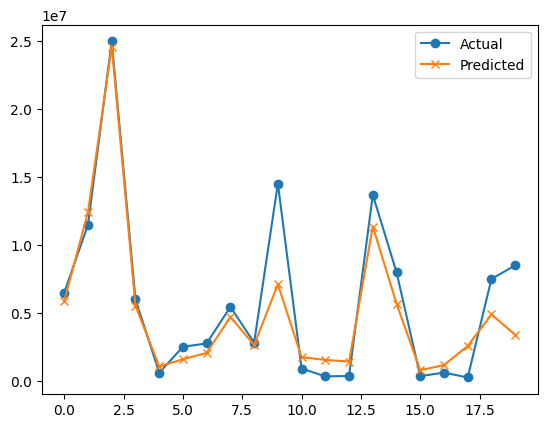

In [444]:
plt.plot(range(20) , y_test[:20] , marker = "o", label="Actual")
plt.plot(range(20) , y_pred[:20],  marker = "x", label="Predicted")
plt.legend()
plt.show()